# Data Preprocessing - Movie Ticket Dataset

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

movies_path = "../Dataset/Movie_Ticket_Assignment3_CSV1_Movies_Messy_500.csv"
shows_path = "../Dataset/Movie_Ticket_Assignment3_CSV2_Shows_Messy_500.csv"
bookings_path = "../Dataset/Movie_Ticket_Assignment3_CSV3_Bookings_Messy_500.csv"

movies = pd.read_csv(movies_path)
shows = pd.read_csv(shows_path)
bookings = pd.read_csv(bookings_path)
print("Movies:", movies.shape, "Shows:", shows.shape, "Bookings:", bookings.shape)

Movies: (500, 11) Shows: (500, 12) Bookings: (500, 15)


## 2. Inspect heads, tails, shape, columns and data types

In [2]:
print("Movies")
display(movies.head(10))
display(movies.tail(5))
print(movies.shape)
print(movies.columns.tolist())
movies.info()

print("Shows")
display(shows.head())
print(shows.shape)
shows.info()

print("Bookings")
display(bookings.head())
print(bookings.shape)
bookings.info()

Movies


,Movie_ID,Movie_Name,Genre,Language,Certificate,Duration_Min,Release_Date,Production_Budget,Director,Rating,Movie_Status
0,M283,Hidden Truth,Romance,Telugu,A,124.0,2024-07-25,43000000.0,R. Sharma,8.9,Upcoming
1,M497,The Great Escape,Animation,English,A,162.0,2024-11-14,15000000.0,S. Kapoor,5.8,Active
2,M274,The Last Chapter,Animation,English,A,121.0,2025-10-06,16000000.0,R. Sharma,7.0,Active
3,M374,Warrior Rising,Animation,Hindi,A,117.0,2025-08-29,60000000.0,P. Joshi,8.2,Upcoming
4,M041,Family First,Drama,Hindi,A,117.0,2024-01-10,137000000.0,P. Joshi,7.9,Active
5,M047,Love Again,Romance,English,A,146.0,2026-02-28,149000000.0,M. Desai,6.4,Upcoming
6,M376,Shadow House,Romance,Malayalam,UA,157.0,2025-04-13,171000000.0,K. Iyer,6.1,Upcoming
7,M050,Final Verdict,NaN,Marathi,A,142.0,2024-08-03,166000000.0,S. Kapoor,4.9,Active
8,M119,Beyond the Stars,Horror,Kannada,U,116.0,2026-02-13,76000000.0,S. Kapoor,8.4,Completed
9,M461,Love Again,Drama,Kannada,A,136.0,2025-08-23,26000000.0,K. Iyer,9.4,Upcoming


,Movie_ID,Movie_Name,Genre,Language,Certificate,Duration_Min,Release_Date,Production_Budget,Director,Rating,Movie_Status
495,M408,City Lights,Comedy,Tamil,A,177.0,2026-15-01,121000000.0,N. Patel,6.8,Active
496,M386,Hidden Truth,Sci-Fi,Telugu,U,187.0,2026-03-04,192000000.0,V. Rao,7.2,Upcoming
497,M437,Love Again,Thriller,Marathi,UA,130.0,2025-11-09,213000000.0,M. Desai,9.0,Active
498,M198,Shadow House,Sci-Fi,Malayalam,U,154.0,2025-04-06,173000000.0,S. Kapoor,7.2,Active
499,M069,The Great Escape,Animation,Kannada,A,147.0,2025-09-19,48000000.0,V. Rao,7.4,Completed


(500, 11)
['Movie_ID', 'Movie_Name', 'Genre', 'Language', 'Certificate', 'Duration_Min', 'Release_Date', 'Production_Budget', 'Director', 'Rating', 'Movie_Status']
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Movie_ID           500 non-null    str    
 1   Movie_Name         500 non-null    str    
 2   Genre              492 non-null    str    
 3   Language           492 non-null    str    
 4   Certificate        500 non-null    str    
 5   Duration_Min       499 non-null    float64
 6   Release_Date       499 non-null    str    
 7   Production_Budget  494 non-null    float64
 8   Director           494 non-null    str    
 9   Rating             495 non-null    float64
 10  Movie_Status       500 non-null    str    
dtypes: float64(3), str(8)
memory usage: 43.1 KB
Shows


,Show_ID,Movie_ID,Cinema_ID,Cinema_Name,City,State,Screen_No,Show_Date,Show_Time,Show_Type,Total_Seats,Ticket_Price
0,S0380,M363,C004,PVR Downtown,Bengaluru,Karnataka,5,2025-03-29,06:30 PM,2D,180.0,280.0
1,S0286,M273,C005,INOX Riverside,Ahmedabad,Gujarat,5,2026-05-10,09:30 PM,2D,150.0,NaN
2,S0086,M151,C008,INOX Metro,Chennai,Tamil Nadu,7,2025-02-04,03:30 PM,IMAX,220.0,320.0
3,S0376,M404,C009,Cinepolis Arena,Jaipur,Rajasthan,1,2025-12-15,12:30 PM,3D,180.0,320.0
4,S0311,NaN,C004,PVR Downtown,Bengaluru,Karnataka,5,2026-05-06,12:30 PM,3D,120.0,220.0


(500, 12)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Show_ID       500 non-null    str    
 1   Movie_ID      493 non-null    str    
 2   Cinema_ID     500 non-null    str    
 3   Cinema_Name   495 non-null    str    
 4   City          494 non-null    str    
 5   State         500 non-null    str    
 6   Screen_No     500 non-null    int64  
 7   Show_Date     495 non-null    str    
 8   Show_Time     496 non-null    str    
 9   Show_Type     500 non-null    str    
 10  Total_Seats   499 non-null    float64
 11  Ticket_Price  494 non-null    float64
dtypes: float64(2), int64(1), str(9)
memory usage: 47.0 KB
Bookings


,Booking_ID,Show_ID,Booking_Date,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Tickets,Ticket_Amount,Discount,Convenience_Fee,Final_Amount,Payment_Mode,Booking_Status,Booking_Channel
0,B00218,S0329,2025-08-20,C0099,Vivaan Shah,65.0,Female,5.0,1600,100.0,30,1530,Card,Cancelled,Website
1,B00240,S0255,2026-04-20,C0131,Aditya Mehta,61.0,Male,3.0,1350,75.0,30,1305,Card,Confirmed,App
2,B00210,S0424,2026-07-26,C0048,Priya Joshi,20.0,Male,2.0,1000,120.0,40,920,Wallet,Cancelled,Counter
3,B00466,S0276,2025-06-07,C0200,Sneha Sharma,54.0,Female,2.0,360,0.0,20,380,Cash,Confirmed,Counter
4,B00290,S0375,2025-06-04,C0081,Riya Patel,46.0,Female,5.0,1400,20.0,30,1410,UPI,Confirmed,App


(500, 15)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Booking_ID       500 non-null    str    
 1   Show_ID          493 non-null    str    
 2   Booking_Date     499 non-null    str    
 3   Customer_ID      500 non-null    str    
 4   Customer_Name    494 non-null    str    
 5   Customer_Age     492 non-null    float64
 6   Customer_Gender  495 non-null    str    
 7   Tickets          495 non-null    float64
 8   Ticket_Amount    500 non-null    int64  
 9   Discount         494 non-null    float64
 10  Convenience_Fee  500 non-null    int64  
 11  Final_Amount     500 non-null    int64  
 12  Payment_Mode     494 non-null    str    
 13  Booking_Status   500 non-null    str    
 14  Booking_Channel  495 non-null    str    
dtypes: float64(3), int64(3), str(9)
memory usage: 58.7 KB


## 3. Descriptive statistics

In [3]:
display(movies.describe(include="all").T)
display(shows.describe(include="all").T)
display(bookings.describe(include="all").T)

# Group aggregates
print("Average rating by genre:")
display(movies.groupby("Genre")["Rating"].mean().sort_values(ascending=False))
print("Total tickets by city:")
display(bookings.merge(shows, on="Show_ID", how="left").groupby("City")["Tickets"].sum().sort_values(ascending=False))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Movie_ID,500,488,M283,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Movie_Name,500,20,Laugh Out Loud,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genre,492,14,Drama,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Language,492,12,Tamil,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Certificate,500,7,A,181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration_Min,499.0,NaN,NaN,NaN,142.47495,48.2447,-20.0,119.0,139.0,165.0,999.0
Release_Date,499,370,2024-04-09,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Production_Budget,494.0,NaN,NaN,NaN,124192307.692308,206745410.513256,8000000.0,61250000.0,105000000.0,165000000.0,3800000000.0
Director,494,8,S. Kapoor,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,495.0,NaN,NaN,NaN,7.00101,1.249283,0.2,6.2,7.0,7.8,15.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Show_ID,500,488,S0465,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Movie_ID,493,310,M041,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cinema_ID,500,10,C003,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cinema_Name,495,14,Cinepolis Mall,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,494,15,Delhi,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,500,11,Gujarat,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Screen_No,500.0,NaN,NaN,NaN,4.882,6.394831,0.0,3.0,4.5,6.0,99.0
Show_Date,495,331,2025-02-11,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Show_Time,496,10,09:30 PM,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Show_Type,500,7,3D,169,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Booking_ID,500,485,B00365,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Show_ID,493,316,S0268,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Booking_Date,499,345,2025-03-02,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,500,212,C0230,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,494,212,Arjun Kapoor,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Age,492.0,NaN,NaN,NaN,41.656504,15.315218,-5.0,30.0,42.0,54.0,145.0
Customer_Gender,495,9,Male,169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tickets,495.0,NaN,NaN,NaN,3.018182,3.793462,0.0,2.0,3.0,4.0,80.0
Ticket_Amount,500.0,NaN,NaN,NaN,957.76,600.276642,180.0,500.0,800.0,1350.0,3000.0
Discount,494.0,NaN,NaN,NaN,69.451417,449.697312,-100.0,0.0,50.0,75.0,9999.0


Average rating by genre:


Genre
Drama        9.100000
thriller     8.300000
 ACTION      7.400000
Drama        7.161538
Sci-Fi       7.126531
Animation    7.097959
Action       7.079310
Adventure    7.052083
Comedy       6.992157
Horror       6.963158
Romance      6.847273
Thriller     6.648000
comedy       6.500000
action       6.000000
Name: Rating, dtype: float64

Total tickets by city:


City
Kolkata      218.0
Hyderabad    175.0
Ahmedabad    165.0
Chennai      159.0
Bengaluru    140.0
Delhi        140.0
Pune         138.0
Surat        129.0
Jaipur       113.0
Mumbai       112.0
Delhi          8.0
PUNE           5.0
 Mumbai        4.0
Name: Tickets, dtype: float64

## 4. Missing values and duplicates

In [4]:
for name, df in [("Movies", movies), ("Shows", shows), ("Bookings", bookings)]:
    print(name)
    display(pd.DataFrame({
        "Missing": df.isna().sum(),
        "Missing %": (df.isna().mean() * 100).round(2),
        "Duplicate rows": df.duplicated().sum()
    }))

Movies


,Missing,Missing %,Duplicate rows
Movie_ID,0,0.0,7
Movie_Name,0,0.0,7
Genre,8,1.6,7
Language,8,1.6,7
Certificate,0,0.0,7
Duration_Min,1,0.2,7
Release_Date,1,0.2,7
Production_Budget,6,1.2,7
Director,6,1.2,7
Rating,5,1.0,7


Shows


,Missing,Missing %,Duplicate rows
Show_ID,0,0.0,6
Movie_ID,7,1.4,6
Cinema_ID,0,0.0,6
Cinema_Name,5,1.0,6
City,6,1.2,6
State,0,0.0,6
Screen_No,0,0.0,6
Show_Date,5,1.0,6
Show_Time,4,0.8,6
Show_Type,0,0.0,6


Bookings


,Missing,Missing %,Duplicate rows
Booking_ID,0,0.0,7
Show_ID,7,1.4,7
Booking_Date,1,0.2,7
Customer_ID,0,0.0,7
Customer_Name,6,1.2,7
Customer_Age,8,1.6,7
Customer_Gender,5,1.0,7
Tickets,5,1.0,7
Ticket_Amount,0,0.0,7
Discount,6,1.2,7


## 5. Clean text columns

In [5]:
movies = movies.copy()
shows = shows.copy()
bookings = bookings.copy()

text_columns = {
    "movies": movies.select_dtypes(include="object").columns,
    "shows": shows.select_dtypes(include="object").columns,
    "bookings": bookings.select_dtypes(include="object").columns,
}
for df, cols in [(movies, text_columns["movies"]), (shows, text_columns["shows"]), (bookings, text_columns["bookings"])]:
    for col in cols:
        df[col] = df[col].astype("string").str.strip()

# Standardize mixed booking-status values
bookings["Booking_Status"] = (
    bookings["Booking_Status"].str.lower().str.strip()
    .replace({"cancelled": "Cancelled", "canceled": "Cancelled", "confirmed": "Confirmed"})
)

C:\Users\Naitik\AppData\Local\Temp\ipykernel_5412\3479950107.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  "movies": movies.select_dtypes(include="object").columns,
C:\Users\Naitik\AppData\Local\Temp\ipykernel_5412\3479950107.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide

## 6. Remove exact duplicates

In [6]:
before = {name: len(df) for name, df in [("movies", movies), ("shows", shows), ("bookings", bookings)]}
movies = movies.drop_duplicates()
shows = shows.drop_duplicates()
bookings = bookings.drop_duplicates()
after = {"movies": len(movies), "shows": len(shows), "bookings": len(bookings)}
print("Rows before:", before)
print("Rows after:", after)

Rows before: {'movies': 500, 'shows': 500, 'bookings': 500}
Rows after: {'movies': 493, 'shows': 494, 'bookings': 493}


## 7. Convert dates and parse show time

In [7]:
movies["Release_Date"] = pd.to_datetime(movies["Release_Date"], format="mixed", dayfirst=False, errors="coerce")
shows["Show_Date"] = pd.to_datetime(shows["Show_Date"], format="mixed", dayfirst=False, errors="coerce")
bookings["Booking_Date"] = pd.to_datetime(bookings["Booking_Date"], format="mixed", dayfirst=False, errors="coerce")

shows["Show_Time_Parsed"] = pd.to_datetime(shows["Show_Time"], format="%I:%M %p", errors="coerce").dt.time

print("Invalid movie dates:", movies["Release_Date"].isna().sum())
print("Invalid show dates:", shows["Show_Date"].isna().sum())
print("Invalid booking dates:", bookings["Booking_Date"].isna().sum())

Invalid movie dates: 5
Invalid show dates: 10
Invalid booking dates: 7


## 8. Handle missing values

In [8]:
for col in ["Genre", "Language", "Director", "Movie_Status"]:
    movies[col] = movies[col].fillna(movies[col].mode().iloc[0])
for col in ["Duration_Min", "Production_Budget", "Rating"]:
    movies[col] = movies[col].fillna(movies[col].median())

for col in ["Cinema_Name", "City", "Show_Time", "Show_Type"]:
    shows[col] = shows[col].fillna(shows[col].mode().iloc[0])
for col in ["Movie_ID", "Ticket_Price", "Total_Seats"]:
    shows[col] = shows[col].fillna(shows[col].median() if pd.api.types.is_numeric_dtype(shows[col]) else shows[col].mode().iloc[0])

for col in ["Customer_Name", "Customer_Gender", "Payment_Mode", "Booking_Channel", "Booking_Status"]:
    bookings[col] = bookings[col].fillna(bookings[col].mode().iloc[0])
for col in ["Customer_Age", "Tickets", "Discount"]:
    bookings[col] = bookings[col].fillna(bookings[col].median())

print("Remaining missing values:",
      movies.isna().sum().sum(), shows.isna().sum().sum(), bookings.isna().sum().sum())

Remaining missing values: 5 14 14


## 9. Remove impossible values and filter ranges

In [9]:
movies = movies[
    (movies["Duration_Min"].between(30, 300)) &
    (movies["Production_Budget"] >= 0) &
    (movies["Rating"].between(0, 10))
]
shows = shows[
    (shows["Total_Seats"].between(1, 500)) &
    (shows["Ticket_Price"] >= 0)
]
bookings = bookings[
    (bookings["Customer_Age"].between(5, 100)) &
    (bookings["Tickets"].between(1, 20)) &
    (bookings["Ticket_Amount"] >= 0) &
    (bookings["Final_Amount"] >= 0)
]
print(movies.shape, shows.shape, bookings.shape)

(490, 11) (492, 13) (488, 15)


## 10. IQR outlier detection

In [10]:
def iqr_outliers(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = ~df[column].between(lower, upper)
    return df.loc[mask, [column]], lower, upper

for name, df, col in [
    ("Production budget", movies, "Production_Budget"),
    ("Ticket price", shows, "Ticket_Price"),
    ("Final amount", bookings, "Final_Amount"),
]:
    outliers, lower, upper = iqr_outliers(df, col)
    print(name, "bounds:", round(lower, 2), round(upper, 2), "outliers:", len(outliers))

Production budget bounds: -91875000.0 319125000.0 outliers: 2
Ticket price bounds: 25.0 625.0 outliers: 2
Final amount bounds: -795.0 2565.0 outliers: 10


## 11. Sorting and filtering examples

In [11]:
print("Top 10 highest-budget movies")
display(movies.nlargest(10, "Production_Budget")[["Movie_Name", "Genre", "Production_Budget", "Rating"]])

print("Long action movies")
display(movies[(movies["Genre"].str.contains("Action", case=False, na=False)) &
               (movies["Duration_Min"] > 150)].head())

print("Confirmed bookings above 1000")
display(bookings[(bookings["Booking_Status"] == "Confirmed") &
                 (bookings["Final_Amount"] > 1000)].head())

Top 10 highest-budget movies


,Movie_Name,Genre,Production_Budget,Rating
183,Dream Beyond,Sci-Fi,3.800000e+09,7.1
366,Dream Beyond,Comedy,2.500000e+09,7.8
157,Mumbai Diaries,Romance,2.200000e+08,6.1
294,Ocean's Secret,Sci-Fi,2.200000e+08,6.3
379,Love Again,Thriller,2.200000e+08,5.4
422,Hidden Truth,Sci-Fi,2.200000e+08,5.5
49,The Great Escape,Horror,2.190000e+08,5.5
227,City Lights,Comedy,2.190000e+08,6.3
325,Shadow House,Drama,2.190000e+08,7.5
450,The Last Chapter,Sci-Fi,2.190000e+08,9.5


Long action movies


,Movie_ID,Movie_Name,Genre,Language,Certificate,Duration_Min,Release_Date,Production_Budget,Director,Rating,Movie_Status
16,M176,Dream Beyond,Action,English,UA,179.0,2025-11-04,203000000.0,P. Joshi,8.0,Completed
22,M236,The Silent Code,Action,English,A,176.0,2025-06-09,208000000.0,V. Rao,7.8,Active
34,M008,Laugh Out Loud,Action,Malayalam,U,188.0,2024-07-15,82000000.0,R. Sharma,7.9,Active
38,M337,Midnight Express,action,Malayalam,A,187.0,2024-08-19,16000000.0,R. Sharma,6.0,Completed
44,M087,The Forgotten Road,Action,Tamil,UA,152.0,2025-10-25,35000000.0,M. Desai,8.1,Completed


Confirmed bookings above 1000


,Booking_ID,Show_ID,Booking_Date,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Tickets,Ticket_Amount,Discount,Convenience_Fee,Final_Amount,Payment_Mode,Booking_Status,Booking_Channel
1,B00240,S0255,2026-04-20,C0131,Aditya Mehta,61.0,Male,3.0,1350,75.0,30,1305,Card,Confirmed,App
4,B00290,S0375,2025-06-04,C0081,Riya Patel,46.0,Female,5.0,1400,20.0,30,1410,UPI,Confirmed,App
15,B00017,S0029,2025-05-30,C0152,Riya Shah,17.0,Male,6.0,2700,120.0,20,2600,Cash,Confirmed,Website
21,B00309,S0299,2026-02-21,C0162,Priya Iyer,17.0,Female,5.0,1400,100.0,40,1340,Wallet,Confirmed,Counter
23,B00275,S0265,2025-01-26,C0011,Rahul Rao,38.0,Female,4.0,1120,0.0,40,1160,Wallet,Confirmed,Counter


## 12. Unique values and frequency counts

In [12]:
for df, col in [
    (movies, "Genre"), (movies, "Language"), (shows, "City"),
    (shows, "Show_Type"), (bookings, "Payment_Mode"),
    (bookings, "Booking_Status")
]:
    print(col, "unique:", df[col].nunique())
    display(df[col].value_counts().head(10))

Genre unique: 13


Genre
Drama        74
Action       57
Horror       55
Romance      54
Comedy       51
Sci-Fi       50
Animation    49
Thriller     49
Adventure    47
action        1
Name: count, dtype: Int64

Language unique: 11


Language
Tamil        93
Kannada      82
Telugu       68
Malayalam    65
Marathi      63
English      58
Hindi        57
ENGLISH       1
hindi         1
marathi       1
Name: count, dtype: Int64

City unique: 13


City
Delhi        62
Surat        54
Hyderabad    51
Bengaluru    49
Ahmedabad    48
Kolkata      47
Chennai      46
Pune         46
Jaipur       45
Mumbai       41
Name: count, dtype: Int64

... (2 outputs left out)

Payment_Mode unique: 10


Payment_Mode
Cash      137
Wallet    118
UPI       117
Card      110
CARD        1
CASH        1
wallet      1
cash        1
card        1
upi         1
Name: count, dtype: Int64

Booking_Status unique: 2


Booking_Status
Confirmed    248
Cancelled    240
Name: count, dtype: Int64

## 13. Create derived columns

In [13]:
movies["Release_Year"] = movies["Release_Date"].dt.year
movies["Release_Month"] = movies["Release_Date"].dt.month
movies["Release_Month_Name"] = movies["Release_Date"].dt.month_name()

shows["Show_Year"] = shows["Show_Date"].dt.year
shows["Show_Month"] = shows["Show_Date"].dt.month
shows["Show_Day"] = shows["Show_Date"].dt.day_name()

bookings["Booking_Year"] = bookings["Booking_Date"].dt.year
bookings["Booking_Month"] = bookings["Booking_Date"].dt.month
bookings["Booking_Day"] = bookings["Booking_Date"].dt.day_name()
bookings["Age_Group"] = pd.cut(
    bookings["Customer_Age"],
    bins=[0, 18, 30, 45, 60, 100],
    labels=["Child/Teen", "18-30", "31-45", "46-60", "60+"],
    include_lowest=True
)

## 14. Arithmetic and validation columns

In [14]:
bookings["Calculated_Final"] = (
    bookings["Ticket_Amount"] - bookings["Discount"] + bookings["Convenience_Fee"]
)
bookings["Amount_Matches"] = (
    np.isclose(bookings["Calculated_Final"], bookings["Final_Amount"])
)
print("Amount mismatch count:", (~bookings["Amount_Matches"]).sum())
display(bookings[["Ticket_Amount", "Discount", "Convenience_Fee",
                  "Calculated_Final", "Final_Amount", "Amount_Matches"]].head())

Amount mismatch count: 17


,Ticket_Amount,Discount,Convenience_Fee,Calculated_Final,Final_Amount,Amount_Matches
0,1600,100.0,30,1530.0,1530,True
1,1350,75.0,30,1305.0,1305,True
2,1000,120.0,40,920.0,920,True
3,360,0.0,20,380.0,380,True
4,1400,20.0,30,1410.0,1410,True


## 15. GroupBy aggregations and pivot tables

In [15]:
movie_summary = movies.groupby("Genre").agg(
    Movie_Count=("Movie_ID", "count"),
    Average_Rating=("Rating", "mean"),
    Average_Budget=("Production_Budget", "mean"),
).sort_values("Movie_Count", ascending=False)
display(movie_summary)

combined = bookings.merge(shows, on="Show_ID", how="left", suffixes=("", "_show"))
combined = combined.merge(movies, on="Movie_ID", how="left", suffixes=("", "_movie"))

pivot = pd.pivot_table(
    combined,
    index="Genre",
    columns="Booking_Status",
    values="Final_Amount",
    aggfunc="sum",
    fill_value=0,
)
display(pivot)

,Movie_Count,Average_Rating,Average_Budget
Genre,,,
Drama,74,7.133784,1.134054e+08
Action,57,7.085965,1.138772e+08
Horror,55,6.947273,1.023091e+08
Romance,54,6.859259,1.224630e+08
Comedy,51,6.992157,1.663137e+08
Sci-Fi,50,7.084000,1.870800e+08
Thriller,49,6.651020,1.136531e+08
Animation,49,6.934694,1.002653e+08
Adventure,47,7.051064,1.110000e+08


Booking_Status,Cancelled,Confirmed
Genre,,
Action,25920,27610
Adventure,26690,31080
Animation,12740,25905
Comedy,27405,17115
Drama,33985,127215
Horror,22915,22010
Romance,20655,20680
Sci-Fi,23815,19280
Thriller,34915,29175


## 16. Merge all three CSV files

In [16]:
merged = bookings.merge(
    shows, on="Show_ID", how="left", suffixes=("", "_show")
).merge(
    movies, on="Movie_ID", how="left", suffixes=("", "_movie")
)
print("Merged shape:", merged.shape)
display(merged.head())

Merged shape: (513, 49)


,Booking_ID,Show_ID,Booking_Date,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Tickets,Ticket_Amount,Discount,Convenience_Fee,Final_Amount,Payment_Mode,Booking_Status,Booking_Channel,Booking_Year,Booking_Month,Booking_Day,Age_Group,Calculated_Final,Amount_Matches,Movie_ID,Cinema_ID,Cinema_Name,City,State,Screen_No,Show_Date,Show_Time,Show_Type,Total_Seats,Ticket_Price,Show_Time_Parsed,Show_Year,Show_Month,Show_Day,Movie_Name,Genre,Language,Certificate,Duration_Min,Release_Date,Production_Budget,Director,Rating,Movie_Status,Release_Year,Release_Month,Release_Month_Name
0,B00218,S0329,2025-08-20,C0099,Vivaan Shah,65.0,Female,5.0,1600,100.0,30,1530,Card,Cancelled,Website,2025.0,8.0,Wednesday,60+,1530.0,True,M020,C006,Cinepolis Square,Hyderabad,Telangana,4.0,2025-08-17,10:00 AM,2D,100.0,500.0,10:00:00,2025.0,8.0,Sunday,The Silent Code,Adventure,Kannada,A,90.0,2025-01-17,161000000.0,K. Iyer,5.3,Completed,2025.0,1.0,January
1,B00240,S0255,2026-04-20,C0131,Aditya Mehta,61.0,Male,3.0,1350,75.0,30,1305,Card,Confirmed,App,2026.0,4.0,Monday,60+,1305.0,True,M097,C010,PVR Galaxy,Surat,Gujarat,8.0,2025-10-16,09:30 PM,2D,220.0,320.0,21:30:00,2025.0,10.0,Thursday,Shadow House,Thriller,Marathi,U,185.0,2024-08-24,145000000.0,S. Kapoor,7.4,Active,2024.0,8.0,August
2,B00210,S0424,2026-07-26,C0048,Priya Joshi,20.0,Male,2.0,1000,120.0,40,920,Wallet,Cancelled,Counter,2026.0,7.0,Sunday,18-30,920.0,True,M178,C004,PVR Downtown,Bengaluru,Karnataka,6.0,2025-04-22,10:00 AM,2D,220.0,320.0,10:00:00,2025.0,4.0,Tuesday,The Last Mission,Drama,Malayalam,A,117.0,2024-05-25,104000000.0,M. Desai,8.7,Completed,2024.0,5.0,May
3,B00466,S0276,2025-06-07,C0200,Sneha Sharma,54.0,Female,2.0,360,0.0,20,380,Cash,Confirmed,Counter,2025.0,6.0,Saturday,46-60,380.0,True,M333,C010,PVR Galaxy,Surat,Gujarat,3.0,2026-06-18,12:30 PM,3D,200.0,350.0,12:30:00,2026.0,6.0,Thursday,The Last Mission,Action,Telugu,A,142.0,2025-05-14,11000000.0,A. Mehta,7.1,Upcoming,2025.0,5.0,May
4,B00290,S0375,2025-06-04,C0081,Riya Patel,46.0,Female,5.0,1400,20.0,30,1410,UPI,Confirmed,App,2025.0,6.0,Wednesday,46-60,1410.0,True,M473,C001,PVR Phoenix,Mumbai,Maharashtra,6.0,2026-04-22,09:30 PM,2D,200.0,350.0,21:30:00,2026.0,4.0,Wednesday,The Forgotten Road,Horror,Malayalam,U,145.0,2024-04-05,175000000.0,S. Kapoor,5.2,Upcoming,2024.0,4.0,April


## 17. Encode categorical columns

In [17]:
categorical_columns = [
    "Genre", "Language", "Certificate", "Movie_Status",
    "City", "State", "Show_Type", "Payment_Mode",
    "Booking_Status", "Booking_Channel", "Age_Group"
]
encoded = pd.get_dummies(
    merged,
    columns=[c for c in categorical_columns if c in merged.columns],
    drop_first=True,
)
print("Shape after one-hot encoding:", encoded.shape)

Shape after one-hot encoding:

 (513, 106)


## 18. Rename and reorder columns

In [18]:
merged = merged.rename(columns={
    "Duration_Min": "Duration_Minutes",
    "Production_Budget": "Production_Budget_INR",
})

priority = [
    "Booking_ID", "Show_ID", "Movie_ID", "Booking_Date", "Customer_ID",
    "Customer_Age", "Tickets", "Final_Amount", "Booking_Status",
]
existing_priority = [c for c in priority if c in merged.columns]
merged = merged[existing_priority + [c for c in merged.columns if c not in existing_priority]]
display(merged.head())

,Booking_ID,Show_ID,Movie_ID,Booking_Date,Customer_ID,Customer_Age,Tickets,Final_Amount,Booking_Status,Customer_Name,Customer_Gender,Ticket_Amount,Discount,Convenience_Fee,Payment_Mode,Booking_Channel,Booking_Year,Booking_Month,Booking_Day,Age_Group,Calculated_Final,Amount_Matches,Cinema_ID,Cinema_Name,City,State,Screen_No,Show_Date,Show_Time,Show_Type,Total_Seats,Ticket_Price,Show_Time_Parsed,Show_Year,Show_Month,Show_Day,Movie_Name,Genre,Language,Certificate,Duration_Minutes,Release_Date,Production_Budget_INR,Director,Rating,Movie_Status,Release_Year,Release_Month,Release_Month_Name
0,B00218,S0329,M020,2025-08-20,C0099,65.0,5.0,1530,Cancelled,Vivaan Shah,Female,1600,100.0,30,Card,Website,2025.0,8.0,Wednesday,60+,1530.0,True,C006,Cinepolis Square,Hyderabad,Telangana,4.0,2025-08-17,10:00 AM,2D,100.0,500.0,10:00:00,2025.0,8.0,Sunday,The Silent Code,Adventure,Kannada,A,90.0,2025-01-17,161000000.0,K. Iyer,5.3,Completed,2025.0,1.0,January
1,B00240,S0255,M097,2026-04-20,C0131,61.0,3.0,1305,Confirmed,Aditya Mehta,Male,1350,75.0,30,Card,App,2026.0,4.0,Monday,60+,1305.0,True,C010,PVR Galaxy,Surat,Gujarat,8.0,2025-10-16,09:30 PM,2D,220.0,320.0,21:30:00,2025.0,10.0,Thursday,Shadow House,Thriller,Marathi,U,185.0,2024-08-24,145000000.0,S. Kapoor,7.4,Active,2024.0,8.0,August
2,B00210,S0424,M178,2026-07-26,C0048,20.0,2.0,920,Cancelled,Priya Joshi,Male,1000,120.0,40,Wallet,Counter,2026.0,7.0,Sunday,18-30,920.0,True,C004,PVR Downtown,Bengaluru,Karnataka,6.0,2025-04-22,10:00 AM,2D,220.0,320.0,10:00:00,2025.0,4.0,Tuesday,The Last Mission,Drama,Malayalam,A,117.0,2024-05-25,104000000.0,M. Desai,8.7,Completed,2024.0,5.0,May
3,B00466,S0276,M333,2025-06-07,C0200,54.0,2.0,380,Confirmed,Sneha Sharma,Female,360,0.0,20,Cash,Counter,2025.0,6.0,Saturday,46-60,380.0,True,C010,PVR Galaxy,Surat,Gujarat,3.0,2026-06-18,12:30 PM,3D,200.0,350.0,12:30:00,2026.0,6.0,Thursday,The Last Mission,Action,Telugu,A,142.0,2025-05-14,11000000.0,A. Mehta,7.1,Upcoming,2025.0,5.0,May
4,B00290,S0375,M473,2025-06-04,C0081,46.0,5.0,1410,Confirmed,Riya Patel,Female,1400,20.0,30,UPI,App,2025.0,6.0,Wednesday,46-60,1410.0,True,C001,PVR Phoenix,Mumbai,Maharashtra,6.0,2026-04-22,09:30 PM,2D,200.0,350.0,21:30:00,2026.0,4.0,Wednesday,The Forgotten Road,Horror,Malayalam,U,145.0,2024-04-05,175000000.0,S. Kapoor,5.2,Upcoming,2024.0,4.0,April


## 19. Export clean and merged data

In [19]:
movies.to_csv("../Output/clean_movies.csv", index=False)
shows.to_csv("../Output/clean_shows.csv", index=False)
bookings.to_csv("../Output/clean_bookings.csv", index=False)
merged.to_csv("../Output/clean_merged_movie_bookings.csv", index=False)
encoded.to_csv("../Output/encoded_merged_movie_bookings.csv", index=False)
print("Files exported to ../Output")

Files exported to ../Output


## 20. Visualization examples

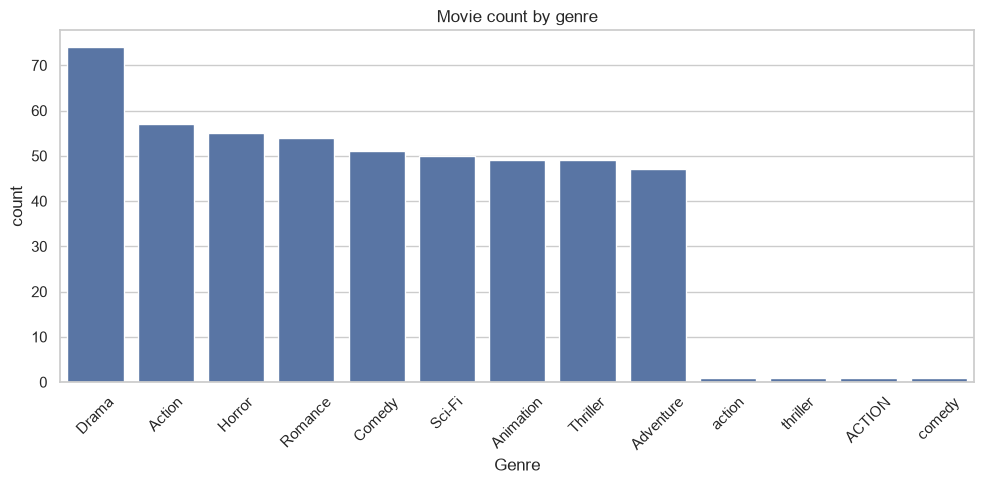

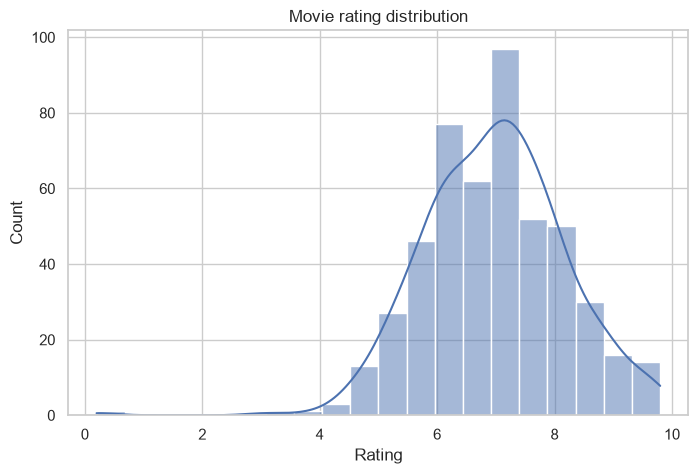

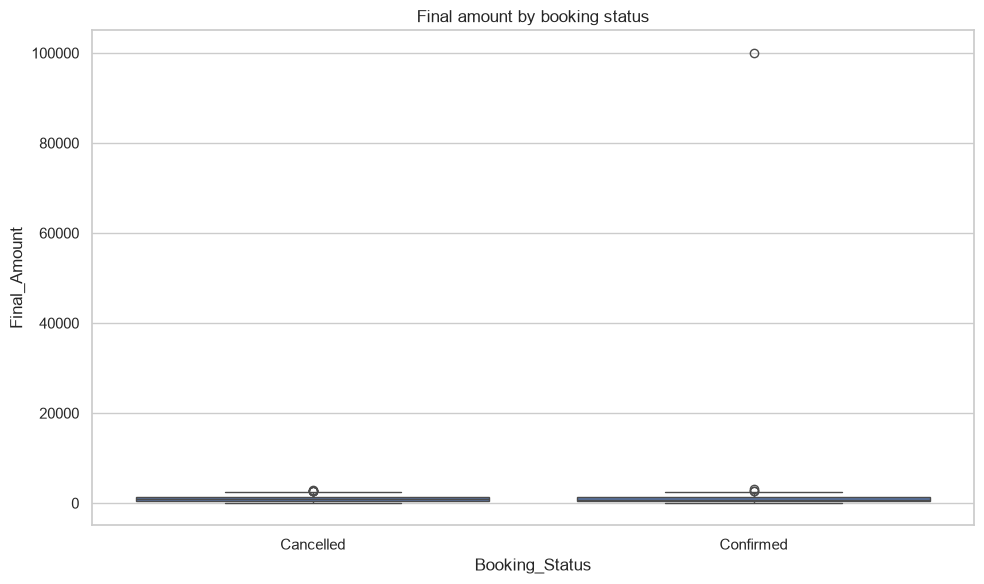

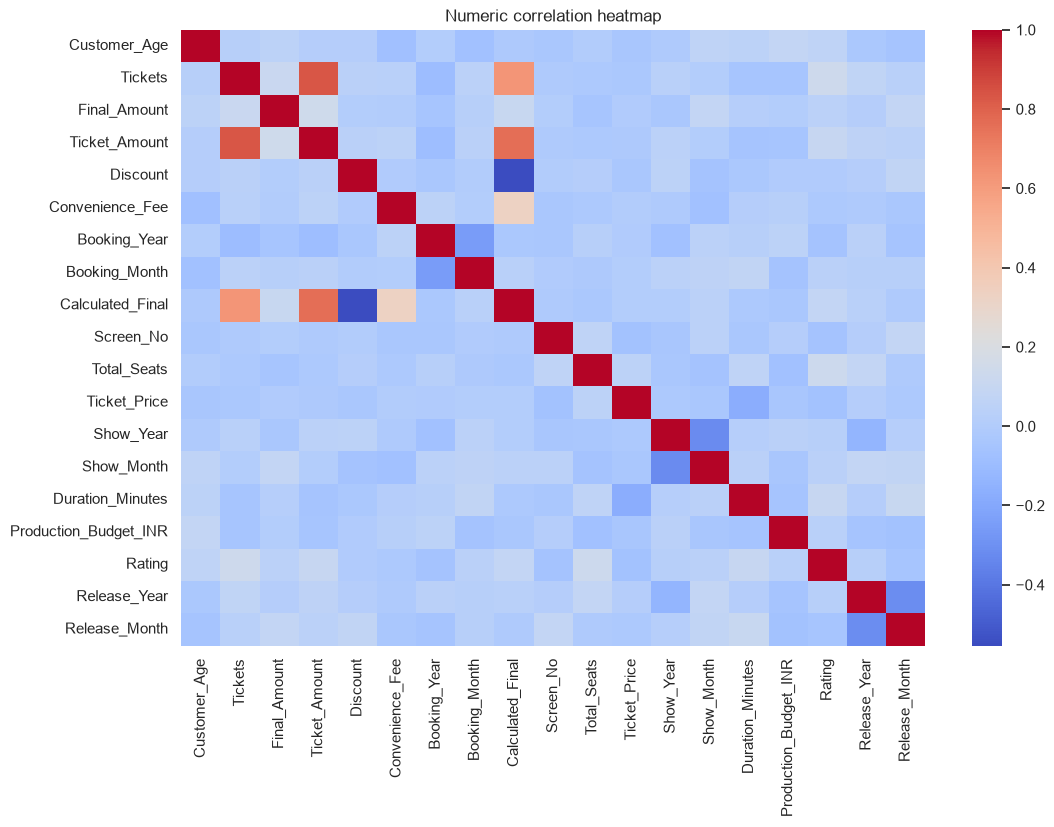

In [20]:
plt.figure(figsize=(10, 5))
sns.countplot(data=movies, x="Genre", order=movies["Genre"].value_counts().index)
plt.xticks(rotation=45)
plt.title("Movie count by genre")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(movies["Rating"].dropna(), bins=20, kde=True)
plt.title("Movie rating distribution")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=merged, x="Booking_Status", y="Final_Amount")
plt.title("Final amount by booking status")
plt.tight_layout()
plt.show()

numeric = merged.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric.corr(), annot=False, cmap="coolwarm")
plt.title("Numeric correlation heatmap")
plt.show()